In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
base_path = '/glade/work/jonahshaw/PRISM_data/'

# Ocean heat content change across the PRISM cases

Every OHC **time series** under `PRISM_data` lives in `spatial_OHC_data/<family>/`; the other OHC files
(`control_baselines_ocn/`, `spatial_maps_ohc/`) are time-mean maps with no time axis, so they can't be plotted
against time. The processing and plotting functions are in `ohc_cases.py` (this directory).

For each case, the global **total** OHC is `OHC_global_mean × ocean_area_m2` (J, full water column), averaged over
each complete year; the plotted quantity is its change since the run's first year, in ZJ (10²¹ J). Ensembles show the
member mean with the min–max range shaded over the years every member covers; where some members run longer, the
mean of the remaining members continues as a thinner line.

In [3]:
import sys
sys.path.insert(0, "/glade/work/wkamp/GEO/PRISM/PRISM/OHC_levels")
import ohc_cases as oc

assert oc.PRISM_DATA == base_path
plt.rcParams.update(oc.STYLE)

cases = oc.discover_cases(base_path + "spatial_OHC_data/")
overview = (cases.assign(files=cases.files.map(len))
            .groupby(["family", "experiment"], sort=False)
            .agg(members=("member", "count"), files=("files", "sum")))
overview.index = overview.index.set_levels(overview.index.levels[1].map(oc.experiment_label), level=1)
print(f"{len(cases)} cases in {len(overview)} experiments, {int(overview.files.sum())} files")
display(overview)

67 cases in 16 experiments, 701 files


members  files
family                   experiment                                     
ARISE-1.0                SSP245-TSMLT-GAUSS-DELAYED-2045       10    250
                         SSP245-TSMLT-GAUSS-LOWER-0.5          10    350
ARISE_SAI                SSP245-G6-1p5K-SAI                     3      3
                         SSP245-TSMLT-ARISE-EXTENDED            2      3
                         SSP245-TSMLT-GAUSS-DEFAULT            10     10
CESM2_LME                PMIP4-PaleoStrat.850CEcontrol          1     19
                         PMIP4-past1000                         1     20
CESM2_WACCM_1850control  CMIP6-piControl                        1      7
CESM2_WACCM_HIST         CMIP6-historical-WACCM                 3      3
CESM2_WACCM_SSP2-4.5     CMIP6-SSP2-4.5-WACCM                  10     20
CESM2_WACCM_SSP2-4.5_MCB CMIP6-MCB-025PCT                       1      1
                         CMIP6-MCB-050PCT                       1      1
                         CMIP6-MCB-075PCT                       1      1
                         CMIP6-MCB-125PCT                       1      1
                         CMIP6-baseline                         1      1
                         MCB-050PCT                            11     11

## Loading and time-coordinate checks

The files are not uniform, so nothing about their time axes is assumed:

- some cases are one file, others are split across up to 35 files (one per year) and are combined on their
  **decoded** time coordinate with `xr.open_mfdataset` — the files encode time against different reference dates
  ("days since" each file's own start year), which decoding reconciles;
- file names are not trusted: e.g. `CMIP6-MCB-025PCT.000…201501-206912.nc` actually holds 2035–2069;
- every combined case must be an unbroken run of first-of-month `noleap` months with no duplicates
  (`ohc_cases.load_case_total` raises otherwise), and only complete 12-month years enter the annual means;
- a member whose data are identical to another member's is dropped — `MCB-050PCT.e11` is a byte-identical copy of
  member `.011` stored under a second case name, and would otherwise count twice.

Loading all cases takes about a minute and a half.

In [4]:
experiments = oc.load_experiments(cases)
summary = oc.summary_table(experiments)
display(summary.style.format({"change_ZJ": "{:+.0f}"}))

  dropped b.e21.BSSP245smbb.f09_g17.MCB-050PCT.e11: identical to member 011


## OHC change by experiment family

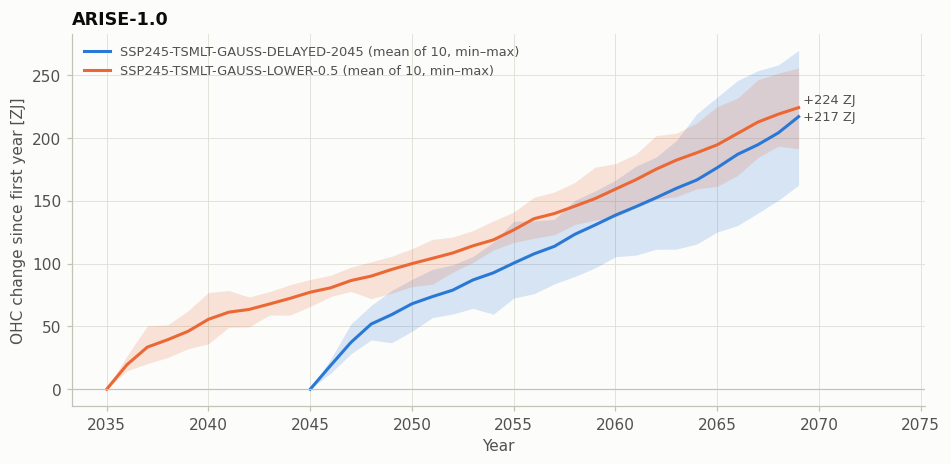

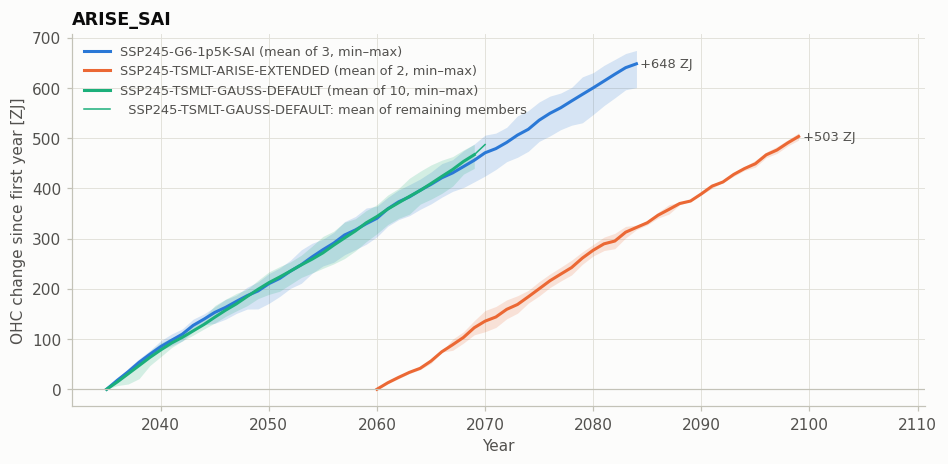

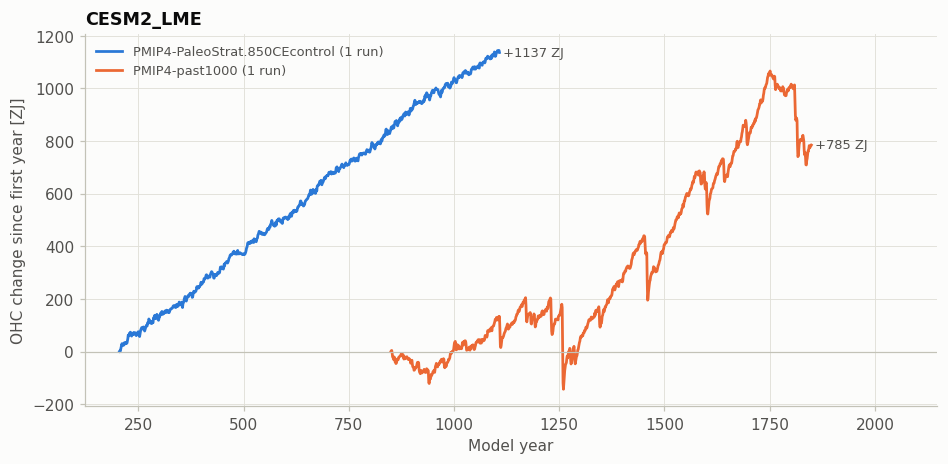

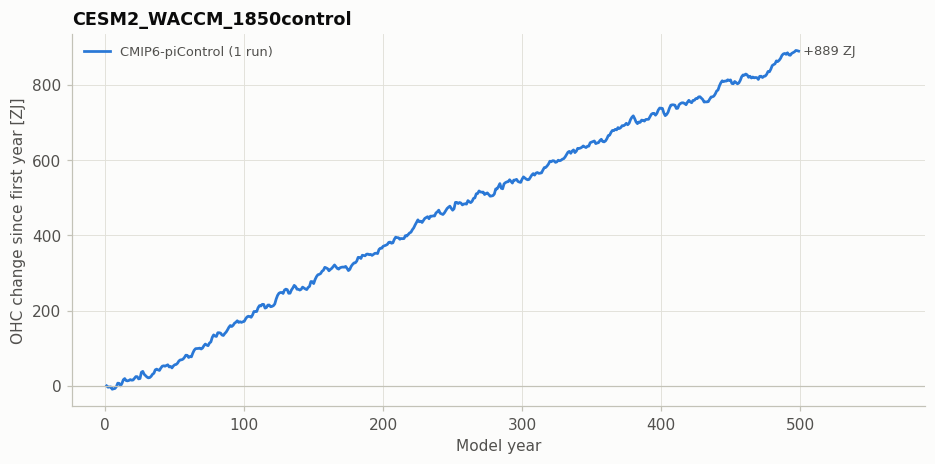

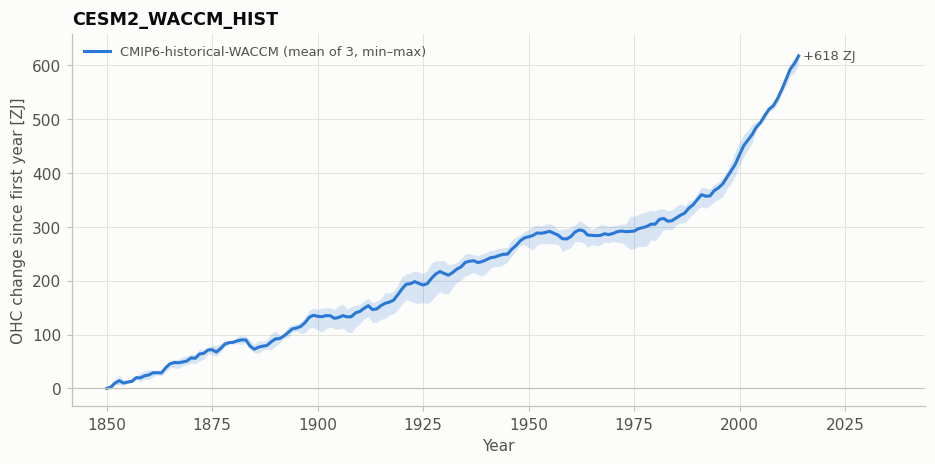

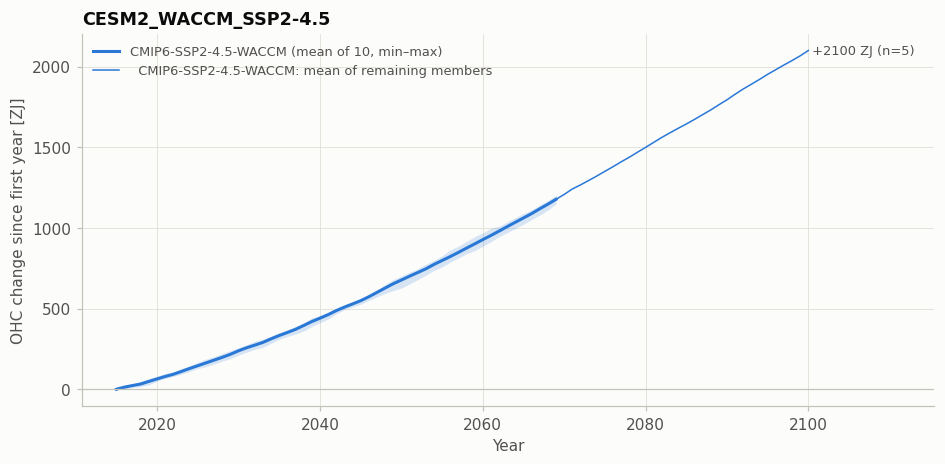

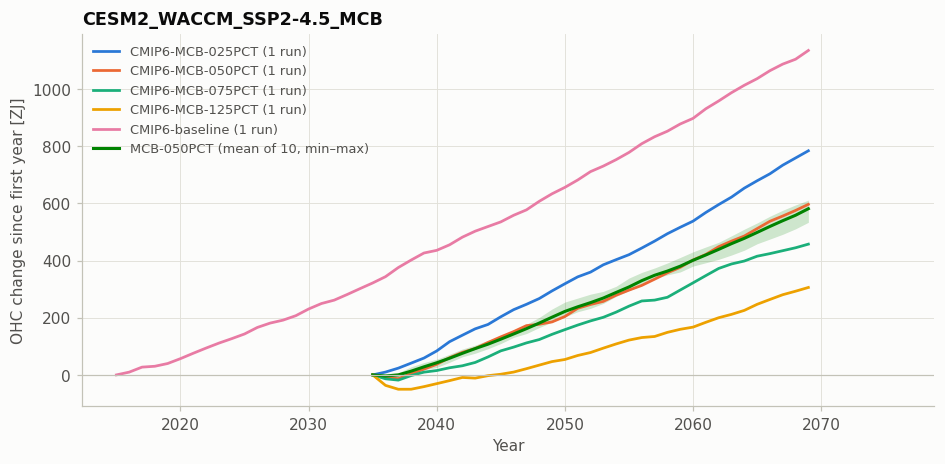

In [5]:
for family in cases["family"].unique():
    fig, ax = plt.subplots(figsize=(10, 4.4))
    oc.plot_family(ax, experiments, family)
    plt.show()

**Reading the plots.** Each curve starts at zero in its own first year, so runs that branch later (e.g. the MCB and
ARISE experiments from 2035, ARISE-EXTENDED from 2060) start from zero later than their parent scenario. To compare
experiments from a shared starting point, re-reference them to a common year, e.g.
`oc.plot_family(ax, experiments, "CESM2_WACCM_SSP2-4.5_MCB", reference_year=2035)`; `per_year=True` plots the
year-to-year change (ZJ/yr) instead of the cumulative change.

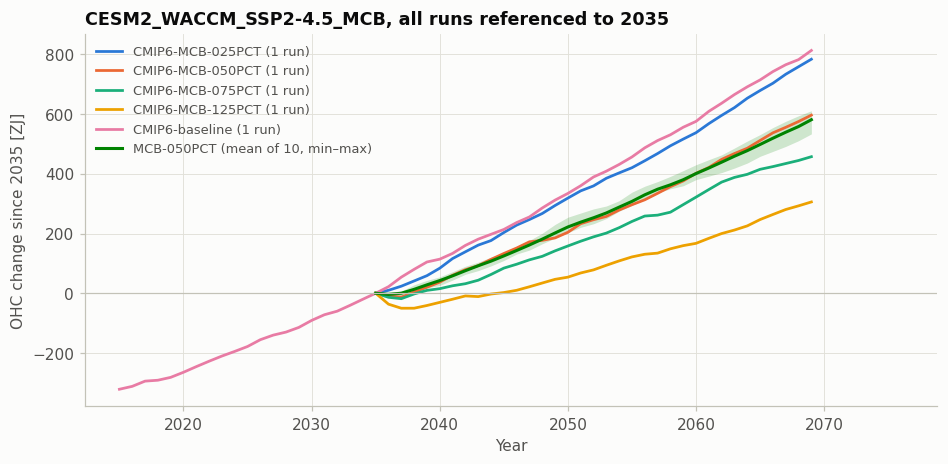

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4))
oc.plot_family(ax, experiments, "CESM2_WACCM_SSP2-4.5_MCB", reference_year=2035)
ax.set_title("CESM2_WACCM_SSP2-4.5_MCB, all runs referenced to 2035")
plt.show()